# 02 · Fourth-Down Risk for an Underdog

- **Audience:** Carolina Panthers head coach (hypothetical stakeholder)
- **Question:** The Panthers are projected underdogs in most of their remaining 2026 games. How much fourth-down risk should the head coach take?
- **Goal:** Find where going for it pays off, whether it pays off more for underdogs, and how Carolina's 2026 decisions compare.
- **As of:** game results and Elo from games final on November 8, 2026 (Weeks 1–8 plus 9 of 15 Week 9 games, including Carolina's); fourth-down play-by-play through Week 8.
- The written summary is in `ANALYTICAL_SUMMARY.md`.

## Context

- Carolina is 3–5 (outscored 199–219) and was the market underdog in 4 of 8 games.
- Our Elo model projects Carolina as the underdog in 6 of its 9 remaining games (model projections, not market lines).
- Through Week 8, Carolina went for it 14 times in 47 fourth downs (6 conversions). In normal situations it went for it on 7 of 29 (24.1%) vs. 16.6% league-wide, 7th of 32. Both samples are small.

## Data and definitions

- **Data:** nflverse via `nflreadpy`: 2018–2025 regular-season play-by-play and schedules (spreads, moneylines), 2026 to date for Carolina, rosters for QB sneaks. Remaining 2026 games use our Elo model (`nflmodel.elo`), not market lines.
- **Underdog:** pregame win probability below 50% (no-vig moneyline; Elo for remaining games).
- **Normal (neutral) situation:** quarters 1–3, score within 8, win probability 10–90%.
- **Went for it:** run or pass on 4th down (fakes included; kneels, spikes, penalty no-plays and aborted kick snaps excluded). **Kicked:** punt or field goal.
- **Zones:** Own 20–40, Midfield, Opp 40–21, Red zone, Goal line. **Distance groups:** 1, 2–3, 4–6, 7+.
- **Minimum sample:** 30 plays; groups below it are flagged.
- **Expected points (EP):** the average points a possession is worth from a given spot (nflfastR).
- All definitions and model inputs are in `definitions.py`.

## 0. Setup & data

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import nflreadpy as nfl

from nflmodel.data import load_games, FRANCHISE_MAP
from nflmodel.elo import run_elo, DEFAULT_PARAMS, elo_diff, predicted_spread

from definitions import (HIST_SEASONS, CURRENT_SEASON, TEAM, MIN_SAMPLE,
                         no_vig_home_prob, spread_group, SPREAD_GROUP_ORDER,
                         is_neutral, decision, field_zone, distance_group, attempt_play_type,
                         AGGR_MAX_YDSTOGO, AGGR_MAX_YARDLINE, AGGR_MIN_PLAYS, aggression_group, AGGR_ORDER,
                         MIN_GO_SHARE, decision_category, DECISION_ORDER,
                         EP_SMOOTH_WINDOW, LONG_YDSTOGO, TD_POINTS, FG_POINTS, PUNT_FIT_DEGREE, PUNT_MIN_YARDLINE,
                         FG_DISTANCE_OFFSET, FG_MAX_DISTANCE, FG_SPOT_BEHIND_LOS, FG_MISS_MIN_SPOT, KICKOFF_SEASONS,
                         DECISION_MARGIN, MARGIN_SENSITIVITY, CHART_YARDLINES, CHART_YDSTOGO, CHART_DECISIONS,
                         yardline_label, AS_OF_DATE, RESULTS_THROUGH_WEEK, PBP_THROUGH_WEEK, SNAPSHOT_DIR)

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

TABLES = Path("outputs/tables")
TABLES.mkdir(parents=True, exist_ok=True)


def save(table, name):
    """Write a summary table to outputs/tables/<name>.csv and return it for display."""
    table.to_csv(TABLES / f"{name}.csv", index=False)
    return table


def sample_flag(n):
    """Label groups below the minimum sample."""
    return np.where(n < MIN_SAMPLE, "insufficient evidence", "")

In [2]:
# Raw pulls are saved once to data/ and reused, so the results stay frozen as of AS_OF_DATE
SEASONS = HIST_SEASONS + [CURRENT_SEASON]
SNAPSHOT = Path(SNAPSHOT_DIR)


def cached(name, pull):
    """Read a saved pull, or pull once and save it."""
    path = SNAPSHOT / f"{name}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    SNAPSHOT.mkdir(exist_ok=True)
    df = pull()
    df.to_parquet(path, index=False)
    return df


PBP_COLS = ["game_id", "play_id", "season", "season_type", "week", "posteam", "defteam",
            "qtr", "down", "ydstogo", "yardline_100", "score_differential",
            "vegas_wp", "vegas_wpa", "epa", "play_type", "qb_kneel", "qb_spike", "aborted_play",
            "qb_scramble", "rusher_player_id", "fourth_down_converted", "fourth_down_failed",
            "fixed_drive", "fixed_drive_result", "posteam_score", "posteam_score_post", "desc",
            "ep", "goal_to_go", "kick_distance", "return_yards", "touchback", "field_goal_result",
            "drive_start_transition"]
pbp = cached("pbp", lambda: nfl.load_pbp(SEASONS).select(PBP_COLS).to_pandas())
schedules = cached("schedules", lambda: nfl.load_schedules(SEASONS).to_pandas())
rosters = cached("rosters", lambda: nfl.load_rosters(SEASONS).to_pandas())

# Regular season; 2026 play-by-play through Week 8
pbp = pbp[(pbp["season_type"] == "REG")
          & ((pbp["season"] < CURRENT_SEASON) | (pbp["week"] <= PBP_THROUGH_WEEK))].reset_index(drop=True)

# Schedules: team codes mapped like the core games table (OAK -> LV); results after the as-of date blanked
schedules = schedules[schedules["game_type"] == "REG"].copy()
schedules[["home_team", "away_team"]] = schedules[["home_team", "away_team"]].replace(FRANCHISE_MAP)
after = schedules["gameday"] > AS_OF_DATE
schedules.loc[after, ["home_score", "away_score"]] = np.nan

# QBs by season (for QB sneaks)
qbs = rosters[rosters["position"] == "QB"]
qb_ids = set(zip(qbs["season"], qbs["gsis_id"]))

played_2026 = schedules[(schedules["season"] == CURRENT_SEASON) & schedules["home_score"].notna()]
print(f"Plays: {len(pbp):,}  |  2026 play-by-play through Week {pbp.loc[pbp['season'] == CURRENT_SEASON, 'week'].max()}"
      f"  |  2026 results through Week {played_2026['week'].max()} ({len(played_2026)} games, as of {AS_OF_DATE})")

Plays: 392,989  |  2026 play-by-play through Week 8  |  2026 results through Week 9 (130 games, as of 2026-11-08)


**Team-game table:** one row per team per game with market win probability (vig removed), line, underdog status and result.

In [3]:
sch = schedules[["game_id", "season", "week", "home_team", "away_team", "home_score", "away_score",
                 "spread_line", "home_moneyline", "away_moneyline"]].copy()
sch["home_prob"] = no_vig_home_prob(sch["home_moneyline"], sch["away_moneyline"])

# Edge cases: exactly 50%, or the moneyline favorite is not the spread favorite
sch["edge_case"] = (np.isclose(sch["home_prob"], 0.5)
                    | ((sch["home_prob"] < 0.5) & (sch["spread_line"] > 0))
                    | ((sch["home_prob"] > 0.5) & (sch["spread_line"] < 0)))

home = sch.assign(team=sch["home_team"], opponent=sch["away_team"], is_home=True,
                  team_prob=sch["home_prob"], team_line=sch["spread_line"],
                  points_for=sch["home_score"], points_against=sch["away_score"])
away = sch.assign(team=sch["away_team"], opponent=sch["home_team"], is_home=False,
                  team_prob=1 - sch["home_prob"], team_line=-sch["spread_line"],
                  points_for=sch["away_score"], points_against=sch["home_score"])
team_games = pd.concat([home, away], ignore_index=True)

# Result: 1 win, 0.5 tie, 0 loss (NaN if not played yet)
played = team_games["points_for"].notna()
team_games["win"] = np.where(team_games["points_for"] > team_games["points_against"], 1.0,
                             np.where(team_games["points_for"] == team_games["points_against"], 0.5, 0.0))
team_games.loc[~played, "win"] = np.nan

# Status and spread group (blank for edge cases and games without a line)
has_line = team_games["team_prob"].notna() & ~team_games["edge_case"]
team_games["status"] = np.where(team_games["team_prob"] < 0.5, "Underdog", "Favorite")
team_games["spread_group"] = spread_group(team_games["team_line"])
team_games.loc[~has_line, ["status", "spread_group"]] = None

team_games = team_games[["game_id", "season", "week", "team", "opponent", "is_home", "points_for",
                         "points_against", "win", "team_prob", "team_line", "status", "spread_group", "edge_case"]]

hist_games = team_games[team_games["season"].isin(HIST_SEASONS)]
print(f"Historical games: {hist_games['game_id'].nunique():,}  |  edge-case games dropped from "
      f"underdog/favorite splits: {hist_games.loc[hist_games['edge_case'], 'game_id'].nunique()}")

Historical games: 2,127  |  edge-case games dropped from underdog/favorite splits: 15


**Fourth-down decisions:** label each fourth down as went for it or kicked, with zone, distance and neutral flag.

In [4]:
fourth = pbp[pbp["down"] == 4].copy()
fourth["decision"], fourth["is_fake"], fourth["aborted_kick"] = decision(fourth)
fourth["zone"] = field_zone(fourth["yardline_100"])
fourth["distance"] = distance_group(fourth["ydstogo"])
fourth["neutral"] = is_neutral(fourth)

# What gets excluded, and why
hist4 = fourth[fourth["season"].isin(HIST_SEASONS)]
print("2018-2025 fourth-down plays:", f"{len(hist4):,}")
print("  not a counted decision (penalty no-plays, kneels, timeouts, etc.):", f"{hist4['decision'].isna().sum():,}")
print("    of which aborted snaps from punt/FG formation:", int(hist4["aborted_kick"].sum()))
print("  counted decisions inside own 20 (excluded):", int((hist4["decision"].notna() & hist4["zone"].isna()).sum()))

# Keep counted decisions outside our own 20
fourth = fourth[fourth["decision"].notna() & fourth["zone"].notna()].copy()
fourth["went"] = fourth["decision"] == "go"
fourth["converted"] = fourth["fourth_down_converted"] == 1

# Attempt play type (QB sneak / other run / pass)
fourth["play_group"] = None
fourth.loc[fourth["went"], "play_group"] = attempt_play_type(fourth[fourth["went"]], qb_ids)

# Pregame status of the team with the ball
fourth = fourth.merge(team_games[["game_id", "team", "status", "spread_group", "team_prob"]],
                      left_on=["game_id", "posteam"], right_on=["game_id", "team"], how="left")
assert fourth["team"].notna().all(), "every play should match a team-game"

hist = fourth[fourth["season"].isin(HIST_SEASONS)]
cur = fourth[fourth["season"] == CURRENT_SEASON]
fakes = hist[hist["is_fake"]]
print(f"\nCounted decisions 2018-2025: {len(hist):,}  (went for it {hist['went'].sum():,}, kicked {(~hist['went']).sum():,})")
print(f"  fake punts/FGs counted as attempts: {len(fakes)} "
      f"({fakes['desc'].str.contains('punt formation', case=False).sum()} from punt formation)")
print(f"  neutral-situation decisions: {hist['neutral'].sum():,}")

2018-2025 fourth-down plays: 31,985
  not a counted decision (penalty no-plays, kneels, timeouts, etc.): 1,946
    of which aborted snaps from punt/FG formation: 19
  counted decisions inside own 20 (excluded): 2590

Counted decisions 2018-2025: 27,449  (went for it 5,622, kicked 21,827)
  fake punts/FGs counted as attempts: 178 (156 from punt formation)
  neutral-situation decisions: 13,512


## A. Panthers 2026 context

Record, remaining games with Elo projections, and fourth-down rates vs. the league. **Found:** 3–5, underdog in 6 of 9 remaining games, 7th-most aggressive in normal situations (small samples).

In [5]:
# A1. Record and results so far (market lines for played games)
car = team_games[(team_games["team"] == TEAM) & (team_games["season"] == CURRENT_SEASON)].sort_values("week")
car_played = car[car["win"].notna()].copy()

wins, losses, ties = (car_played["win"] == 1).sum(), (car_played["win"] == 0).sum(), (car_played["win"] == 0.5).sum()
record = f"{wins}-{losses}" + (f"-{ties}" if ties else "")
print(f"{TEAM} {CURRENT_SEASON} record: {record}  |  points for {car_played['points_for'].sum():.0f}, "
      f"against {car_played['points_against'].sum():.0f}")
print(f"Market underdog in {(car_played['status'] == 'Underdog').sum()} of {len(car_played)} games played")

car_played["home_away"] = np.where(car_played["is_home"], "Home", "Away")
car_played["result"] = car_played["win"].map({1.0: "W", 0.5: "T", 0.0: "L"})
a1 = car_played[["week", "opponent", "home_away", "points_for", "points_against", "result",
                 "team_prob", "team_line", "status"]].rename(columns={"team_prob": "market_win_prob",
                                                                      "team_line": "market_line"})
save(a1, "A_car_2026_results").round(3)

CAR 2026 record: 3-5  |  points for 199, against 219
Market underdog in 4 of 8 games played


,week,opponent,home_away,points_for,points_against,result,market_win_prob,market_line,status
2129,1,CHI,Home,37.0,59.0,L,0.400,-3.0,Underdog
4543,2,ATL,Away,34.0,3.0,W,0.583,2.5,Favorite
4560,3,CLE,Away,18.0,21.0,L,0.551,2.5,Favorite
2189,4,DET,Home,32.0,26.0,W,0.336,-4.5,Underdog
4612,6,PHI,Away,25.0,14.0,W,0.593,3.0,Favorite
2224,7,TB,Home,13.0,43.0,L,0.600,3.0,Favorite
4633,8,GB,Away,19.0,27.0,L,0.369,-3.5,Underdog
2250,9,DEN,Home,21.0,26.0,L,0.417,-3.0,Underdog


In [6]:
# A2. Remaining games: Elo projections from our model's most recent ratings (NOT market lines)
games_all = cached("games", lambda: load_games(2005, CURRENT_SEASON))   # in memory; core data file untouched
future = games_all["kickoff"] > pd.Timestamp(AS_OF_DATE) + pd.Timedelta(days=1)  # treat games after the as-of date as unplayed
games_all.loc[future, ["home_score", "away_score", "result"]] = pd.NA
games_all.loc[future, "home_win"] = np.nan
elo = run_elo(games_all, DEFAULT_PARAMS)

last_played = elo[elo["home_win"].notna()]["kickoff"].max()
left = elo[(elo["season"] == CURRENT_SEASON) & (elo["game_type"] == "REG") & elo["home_win"].isna()
           & ((elo["home_team"] == TEAM) | (elo["away_team"] == TEAM))].copy()

# Unplayed games carry the latest ratings
car_home = left["home_team"] == TEAM
hfa = np.where(left["is_neutral"], DEFAULT_PARAMS["neutral_hfa"], DEFAULT_PARAMS["hfa"])
d_home = elo_diff(left["elo_home_pre"], left["elo_away_pre"], hfa)
home_margin = predicted_spread(d_home, DEFAULT_PARAMS["spread_divisor"])

remaining = pd.DataFrame({
    "week": left["week"].values,
    "opponent": np.where(car_home, left["away_team"], left["home_team"]),
    "home_away": np.where(car_home, "Home", "Away"),
    "car_elo": np.where(car_home, left["elo_home_pre"], left["elo_away_pre"]),
    "opp_elo": np.where(car_home, left["elo_away_pre"], left["elo_home_pre"]),
    "elo_win_prob": np.where(car_home, left["home_prob"], 1 - left["home_prob"]),
    "elo_proj_margin": np.where(car_home, home_margin, -home_margin),   # + = CAR favored by
})
remaining["elo_status"] = np.where(remaining["elo_win_prob"] < 0.5, "Underdog", "Favorite")
remaining["elo_spread_group"] = spread_group(remaining["elo_proj_margin"])
remaining["source"] = "Elo model projection"

print(f"Ratings as of the last completed game: {last_played:%Y-%m-%d}  |  CAR Elo {remaining['car_elo'].iloc[0]:.0f}")
print(f"Remaining games: {len(remaining)}  |  Elo-projected underdog in {(remaining['elo_status'] == 'Underdog').sum()}")
save(remaining, "A_car_2026_remaining_elo_projections").round(3)

Ratings as of the last completed game: 2026-11-08  |  CAR Elo 1425
Remaining games: 9  |  Elo-projected underdog in 6


,week,opponent,home_away,car_elo,opp_elo,elo_win_prob,elo_proj_margin,elo_status,elo_spread_group,source
0,10,NO,Away,1425.239,1421.186,0.446,-1.518,Underdog,Underdog small (1-3),Elo model projection
1,11,BAL,Home,1425.239,1466.226,0.501,0.041,Favorite,Pick'em (<1),Elo model projection
2,12,TB,Away,1425.239,1498.896,0.339,-4.626,Underdog,Underdog moderate (3.5-7),Elo model projection
3,13,MIN,Away,1425.239,1612.363,0.211,-9.165,Underdog,Underdog large (7.5+),Elo model projection
4,14,NO,Home,1425.239,1421.186,0.566,1.842,Favorite,Favorite small (1-3),Elo model projection
5,15,CIN,Home,1425.239,1588.385,0.332,-4.846,Underdog,Underdog moderate (3.5-7),Elo model projection
6,16,PIT,Away,1425.239,1574.499,0.250,-7.650,Underdog,Underdog large (7.5+),Elo model projection
7,17,SEA,Home,1425.239,1614.954,0.299,-5.909,Underdog,Underdog moderate (3.5-7),Elo model projection
8,18,ATL,Home,1425.239,1441.478,0.537,1.030,Favorite,Favorite small (1-3),Elo model projection


In [7]:
# A3. Panthers' 2026 fourth downs vs the 2026 league
def fourth_down_profile(df):
    """Attempts, conversions, and neutral-situation go rate for a set of fourth downs."""
    n = df[df["neutral"]]
    return pd.Series({
        "fourth_downs": len(df),
        "attempts": int(df["went"].sum()),
        "conversions": int(df["converted"].sum()),
        "conversion_rate": df.loc[df["went"], "converted"].mean(),
        "neutral_fourth_downs": len(n),
        "neutral_attempts": int(n["went"].sum()),
        "neutral_go_rate": n["went"].mean(),
    })

a3 = pd.DataFrame({
    TEAM: fourth_down_profile(cur[cur["posteam"] == TEAM]),
    "League (all 32 teams pooled)": fourth_down_profile(cur),
}).T.reset_index(names="group")
count_cols = ["fourth_downs", "attempts", "conversions", "neutral_fourth_downs", "neutral_attempts"]
a3[count_cols] = a3[count_cols].astype(int)
a3["attempts_flag"] = sample_flag(a3["attempts"])            # applies to conversion_rate
a3["neutral_flag"] = sample_flag(a3["neutral_fourth_downs"]) # applies to neutral_go_rate

# Where CAR ranks among the 32 teams on neutral go rate
by_team = cur.groupby("posteam").apply(fourth_down_profile, include_groups=False)
by_team["neutral_go_rate_rank"] = by_team["neutral_go_rate"].rank(ascending=False, method="min")
save(by_team.reset_index().sort_values("neutral_go_rate", ascending=False), "A_team_fourth_down_profile_2026")

print(f"CAR neutral go-rate rank: {by_team.loc[TEAM, 'neutral_go_rate_rank']:.0f} of {len(by_team)}")
save(a3, "A_car_vs_league_fourth_down_2026").round(3)

CAR neutral go-rate rank: 7 of 32


,group,fourth_downs,attempts,conversions,conversion_rate,neutral_fourth_downs,neutral_attempts,neutral_go_rate,attempts_flag,neutral_flag
0,CAR,47,14,6,0.429,29,7,0.241,insufficient evidence,insufficient evidence
1,League (all 32 teams pooled),1556,336,182,0.542,851,141,0.166,,


## B. Where fourth-down attempts succeed (2018–2025)

Go rates, conversion rates, EPA, drive results and the cost of failing. **Found:** distance drives success (67% conversion on 4th & 1, 29% on 4th & 7+); field position matters little; the QB sneak converts 80% on 4th & 1.

In [8]:
# B1. Go rate by distance x zone (neutral situations)
neutral_hist = hist[hist["neutral"]]
b1 = (neutral_hist.groupby(["distance", "zone"], observed=True)
      .agg(fourth_downs=("went", "size"), attempts=("went", "sum"), go_rate=("went", "mean"))
      .reset_index())
b1["sample_flag"] = sample_flag(b1["fourth_downs"])
save(b1, "B_go_rate_by_distance_zone")

b1.pivot(index="distance", columns="zone", values="go_rate").round(3)

zone,Goal line (1-5),Red zone (6-20),Opponent 40-21 (21-40),Midfield (41-60),Own 20-40 (61-80)
distance,,,,,
1,0.912,0.822,0.840,0.758,0.258
2-3,0.358,0.260,0.418,0.283,0.029
4-6,0.081,0.026,0.170,0.080,0.014
7+,NaN,0.003,0.027,0.019,0.005


In [9]:
# B2. Conversion rate by distance, zone, play type, and distance x zone (all attempts)
attempts = hist[hist["went"]]

def conversion_table(by):
    t = (attempts.groupby(by, observed=True)
         .agg(attempts=("converted", "size"), conversions=("converted", "sum"), conversion_rate=("converted", "mean"))
         .reset_index())
    t["sample_flag"] = sample_flag(t["attempts"])
    return t

b2_distance = save(conversion_table(["distance"]), "B_conversion_by_distance")
b2_zone = save(conversion_table(["zone"]), "B_conversion_by_zone")
b2_play = save(conversion_table(["play_group", "distance"]), "B_conversion_by_play_type")
b2_cross = save(conversion_table(["distance", "zone"]), "B_conversion_by_distance_zone")

print(f"Attempts 2018-2025: {len(attempts):,}  |  overall conversion rate {attempts['converted'].mean():.3f}")
display(b2_distance.round(3), b2_zone.round(3), b2_play.round(3))
b2_cross.pivot(index="distance", columns="zone", values="conversion_rate").round(3)

Attempts 2018-2025: 5,622  |  overall conversion rate 0.539


,distance,attempts,conversions,conversion_rate,sample_flag
0,1,2274,1530,0.673,
1,2-3,1352,753,0.557,
2,4-6,975,453,0.465,
3,7+,1021,296,0.290,


,zone,attempts,conversions,conversion_rate,sample_flag
0,Goal line (1-5),643,355,0.552,
1,Red zone (6-20),807,431,0.534,
2,Opponent 40-21 (21-40),1711,909,0.531,
3,Midfield (41-60),1672,919,0.550,
4,Own 20-40 (61-80),789,418,0.530,


,play_group,distance,attempts,conversions,conversion_rate,sample_flag
0,Other run,1,1080,721,0.668,
1,Other run,2-3,221,141,0.638,
2,Other run,4-6,98,63,0.643,
3,Other run,7+,72,32,0.444,
4,Pass,1,591,326,0.552,
5,Pass,2-3,1093,589,0.539,
6,Pass,4-6,877,390,0.445,
7,Pass,7+,949,264,0.278,
8,QB sneak,1,603,483,0.801,
9,QB sneak,2-3,38,23,0.605,


zone,Goal line (1-5),Red zone (6-20),Opponent 40-21 (21-40),Midfield (41-60),Own 20-40 (61-80)
distance,,,,,
1,0.594,0.658,0.684,0.703,0.704
2-3,0.510,0.598,0.555,0.562,0.563
4-6,0.421,0.423,0.458,0.500,0.473
7+,NaN,0.246,0.276,0.301,0.316


In [10]:
# B3. Average EPA per attempt by distance (kicks shown for reference)
kicks = hist[~hist["went"]]
b3 = (attempts.groupby("distance", observed=True)
      .agg(attempts=("epa", "size"), avg_epa_attempt=("epa", "mean"), conversion_rate=("converted", "mean"))
      .join(kicks.groupby("distance", observed=True).agg(kicks=("epa", "size"), avg_epa_kick=("epa", "mean")))
      .reset_index())
b3["sample_flag"] = sample_flag(b3["attempts"])
save(b3, "B_epa_by_distance").round(3)

,distance,attempts,avg_epa_attempt,conversion_rate,kicks,avg_epa_kick,sample_flag
0,1,2274,0.259,0.673,1058,-0.386,
1,2-3,1352,0.432,0.557,2949,-0.111,
2,4-6,975,0.110,0.465,5388,-0.108,
3,7+,1021,-0.646,0.290,12432,0.019,


In [11]:
# B4. Drive results after a converted attempt (one row per converted attempt)
RESULT_MAP = {"Touchdown": "TD", "Field goal": "FG", "Punt": "Punt",
              "Turnover": "Turnover", "Opp touchdown": "Turnover",
              "Turnover on downs": "Turnover on downs"}
converted = attempts[attempts["converted"]].copy()
print(f"Converted attempts: {len(converted):,}")
converted["drive_result"] = converted["fixed_drive_result"].map(RESULT_MAP).fillna("Other (missed FG, end of half, safety)")

def result_shares(df, by):
    t = df.groupby(by + ["drive_result"], observed=True).size().rename("drives").reset_index()
    t["share"] = t["drives"] / t.groupby(by, observed=True)["drives"].transform("sum")
    t["group_total"] = t.groupby(by, observed=True)["drives"].transform("sum")
    t["sample_flag"] = sample_flag(t["group_total"])
    return t

b4_all = result_shares(converted.assign(all="All converted attempts"), ["all"]).rename(columns={"all": "zone"})
b4_zone = result_shares(converted, ["zone"])
b4 = save(pd.concat([b4_all, b4_zone], ignore_index=True), "B_drive_result_after_conversion")
b4.pivot(index="zone", columns="drive_result", values="share").round(3)

Converted attempts: 3,032


drive_result,FG,"Other (missed FG, end of half, safety)",Punt,TD,Turnover,Turnover on downs
zone,,,,,,
All converted attempts,0.188,0.077,0.053,0.522,0.081,0.078
Goal line (1-5),0.017,0.003,NaN,0.966,0.006,0.008
Midfield (41-60),0.233,0.103,0.078,0.371,0.110,0.104
Opponent 40-21 (21-40),0.255,0.099,0.024,0.501,0.054,0.067
Own 20-40 (61-80),0.153,0.077,0.160,0.280,0.177,0.153
Red zone (6-20),0.128,0.037,NaN,0.756,0.046,0.032


In [12]:
# B5. Cost of failure: the opponent's next drive after a failed attempt
# Drive table from every play: who had the ball, where the drive started, and points scored
plays = pbp[pbp["season"].isin(HIST_SEASONS) & pbp["fixed_drive"].notna() & pbp["posteam"].notna()]
plays = plays.sort_values(["game_id", "play_id"])
drives = (plays.groupby(["game_id", "fixed_drive"])
          .agg(drive_team=("posteam", "first"), first_play=("play_type", "first"),
               start_yardline_100=("yardline_100", "first"), score_start=("posteam_score", "first"))
          .reset_index())
end_score = (plays.groupby(["game_id", "fixed_drive", "posteam"])["posteam_score_post"].max()
             .rename("score_end").reset_index())
drives = drives.merge(end_score, left_on=["game_id", "fixed_drive", "drive_team"],
                      right_on=["game_id", "fixed_drive", "posteam"], how="left")
drives["points"] = drives["score_end"] - drives["score_start"]

# Failed attempt -> the next drive in the game, kept only if the opponent has the ball
# and the drive starts from scrimmage (not a kickoff, e.g. after halftime)
failed = attempts[~attempts["converted"]][["game_id", "fixed_drive", "defteam", "zone"]].copy()
failed["next_drive"] = failed["fixed_drive"] + 1
nxt = failed.merge(drives, left_on=["game_id", "next_drive"], right_on=["game_id", "fixed_drive"],
                   how="left", suffixes=("", "_next"))
matched = nxt[(nxt["drive_team"] == nxt["defteam"]) & (nxt["first_play"] != "kickoff")].copy()
print(f"Failed attempts: {len(failed):,}  |  matched to an opponent drive from scrimmage: {len(matched):,}")

def cost_table(df, by):
    t = (df.groupby(by, observed=True)
         .agg(failed_attempts=("points", "size"),
              opp_start_yards_to_end_zone=("start_yardline_100", "mean"),
              opp_avg_points=("points", "mean"),
              opp_td_rate=("points", lambda p: (p >= 6).mean()),
              opp_score_rate=("points", lambda p: (p > 0).mean()))
         .reset_index())
    t["sample_flag"] = sample_flag(t["failed_attempts"])
    return t

b5 = pd.concat([cost_table(matched.assign(zone="All failed attempts"), ["zone"]), cost_table(matched, ["zone"])],
               ignore_index=True)
save(b5, "B_cost_of_failure_next_drive").round(3)

Failed attempts: 2,590  |  matched to an opponent drive from scrimmage: 2,499


,zone,failed_attempts,opp_start_yards_to_end_zone,opp_avg_points,opp_td_rate,opp_score_rate,sample_flag
0,All failed attempts,2499,63.422,1.697,0.180,0.329,
1,Goal line (1-5),281,95.658,1.125,0.117,0.221,
2,Red zone (6-20),371,86.119,1.022,0.113,0.194,
3,Opponent 40-21 (21-40),790,67.005,1.656,0.182,0.310,
4,Midfield (41-60),707,50.161,2.083,0.221,0.403,
5,Own 20-40 (61-80),350,31.813,2.183,0.211,0.451,


## C. Does going for it pay off more for underdogs?

Compares the win-probability change after going vs. kicking in normal situations, for underdogs and favorites, and checks whether aggressive underdogs beat market expectations. **Found:** going for it was associated with gains in most short-yardage spots, but not more for underdogs (larger in 2 of 7 comparable spots), and aggression groups differ by less than their noise.

- Teams choose when to go, so these are associations, not causes.

In [13]:
# C1. Go vs kick: average vegas_wpa by distance x zone, overall and split by status / spread group
neutral_split = neutral_hist[neutral_hist["status"].notna()]

def go_vs_kick(df, by):
    """Average vegas_wpa for go and kick, the difference, its standard error, and counts."""
    g = df.groupby(by + ["decision"], observed=True)["vegas_wpa"].agg(["size", "mean", "var"]).unstack("decision")
    t = pd.DataFrame({
        "go_plays": g[("size", "go")], "go_avg_wpa": g[("mean", "go")],
        "kick_plays": g[("size", "kick")], "kick_avg_wpa": g[("mean", "kick")],
    })
    t[["go_plays", "kick_plays"]] = t[["go_plays", "kick_plays"]].fillna(0).astype(int)
    t["go_minus_kick_wpa"] = t["go_avg_wpa"] - t["kick_avg_wpa"]
    t["std_error"] = np.sqrt(g[("var", "go")] / t["go_plays"] + g[("var", "kick")] / t["kick_plays"])
    t["evidence"] = np.where((t["go_plays"] >= MIN_SAMPLE) & (t["kick_plays"] >= MIN_SAMPLE),
                             "sufficient", "insufficient evidence")
    return t.reset_index()

c1_all = save(go_vs_kick(neutral_hist, ["distance", "zone"]), "C_go_vs_kick_wpa_all_teams")
c1_status = save(go_vs_kick(neutral_split, ["status", "distance", "zone"]), "C_go_vs_kick_wpa_underdog_favorite")
c1_spread = go_vs_kick(neutral_split, ["spread_group", "distance", "zone"])
c1_spread["spread_group"] = pd.Categorical(c1_spread["spread_group"], SPREAD_GROUP_ORDER, ordered=True)
c1_spread = save(c1_spread.sort_values(["spread_group", "distance", "zone"]), "C_go_vs_kick_wpa_spread_group")

print(f"Neutral decisions with a market status: {len(neutral_split):,} "
      f"(underdog {(neutral_split['status'] == 'Underdog').sum():,}, favorite {(neutral_split['status'] == 'Favorite').sum():,})")
c1_status.round(4)

Neutral decisions with a market status: 13,403 (underdog 6,938, favorite 6,465)


,status,distance,zone,go_plays,go_avg_wpa,kick_plays,kick_avg_wpa,go_minus_kick_wpa,std_error,evidence
0,Favorite,1,Goal line (1-5),95,0.0005,11,-0.0147,0.0152,0.0130,insufficient evidence
1,Favorite,1,Red zone (6-20),72,0.0131,15,-0.0023,0.0154,0.0100,insufficient evidence
2,Favorite,1,Opponent 40-21 (21-40),142,0.0132,22,-0.0189,0.0321,0.0124,insufficient evidence
3,Favorite,1,Midfield (41-60),169,0.0197,43,-0.0087,0.0284,0.0062,sufficient
4,Favorite,1,Own 20-40 (61-80),63,0.0211,166,-0.0042,0.0252,0.0083,sufficient
5,Favorite,2-3,Goal line (1-5),44,-0.0086,71,-0.0309,0.0224,0.0135,sufficient
6,Favorite,2-3,Red zone (6-20),35,0.0189,112,-0.0130,0.0319,0.0145,sufficient
7,Favorite,2-3,Opponent 40-21 (21-40),106,0.0054,134,-0.0150,0.0205,0.0093,sufficient
8,Favorite,2-3,Midfield (41-60),70,0.0125,184,-0.0042,0.0167,0.0092,sufficient
9,Favorite,2-3,Own 20-40 (61-80),4,0.0482,293,-0.0015,0.0497,0.0323,insufficient evidence


In [14]:
# C1 side by side: is the go-minus-kick payoff larger for underdogs in the same cell?
dog = c1_status[c1_status["status"] == "Underdog"].set_index(["distance", "zone"])
fav = c1_status[c1_status["status"] == "Favorite"].set_index(["distance", "zone"])
c1_compare = pd.DataFrame({
    "dog_go_plays": dog["go_plays"], "dog_kick_plays": dog["kick_plays"], "dog_go_minus_kick": dog["go_minus_kick_wpa"],
    "fav_go_plays": fav["go_plays"], "fav_kick_plays": fav["kick_plays"], "fav_go_minus_kick": fav["go_minus_kick_wpa"],
})
c1_compare["dog_minus_fav"] = c1_compare["dog_go_minus_kick"] - c1_compare["fav_go_minus_kick"]
c1_compare["both_sufficient"] = (dog["evidence"] == "sufficient") & (fav["evidence"] == "sufficient")
# Also flag cells where both sides pass the evidence rules used in Analysis D (adds the 10% go-share rule)
def passes_evidence_rules(t):
    return (t["evidence"] == "sufficient") & (t["go_plays"] / (t["go_plays"] + t["kick_plays"]) >= MIN_GO_SHARE)
c1_compare["both_pass_evidence_rules"] = passes_evidence_rules(dog) & passes_evidence_rules(fav)
c1_compare = save(c1_compare.reset_index(), "C_underdog_vs_favorite_go_payoff")

ok = c1_compare[c1_compare["both_sufficient"]]
print(f"Cells with enough plays for both underdogs and favorites: {len(ok)} of {len(c1_compare)}")
print(f"  going favored (go minus kick > 0) for underdogs in {(ok['dog_go_minus_kick'] > 0).sum()}, "
      f"for favorites in {(ok['fav_go_minus_kick'] > 0).sum()}")
print(f"  payoff larger for underdogs than favorites in {(ok['dog_minus_fav'] > 0).sum()} of {len(ok)}")
ok2 = c1_compare[c1_compare["both_pass_evidence_rules"]]
print(f"Cells passing the evidence rules (incl. 10% go share) for both: {len(ok2)}  |  "
      f"payoff larger for underdogs in {(ok2['dog_minus_fav'] > 0).sum()} of {len(ok2)}")
c1_compare.round(4)

Cells with enough plays for both underdogs and favorites: 8 of 19
  going favored (go minus kick > 0) for underdogs in 7, for favorites in 8
  payoff larger for underdogs than favorites in 2 of 8
Cells passing the evidence rules (incl. 10% go share) for both: 7  |  payoff larger for underdogs in 2 of 7


,distance,zone,dog_go_plays,dog_kick_plays,dog_go_minus_kick,fav_go_plays,fav_kick_plays,fav_go_minus_kick,dog_minus_fav,both_sufficient,both_pass_evidence_rules
0,1,Goal line (1-5),100,8,0.0390,95,11,0.0152,0.0238,False,False
1,1,Red zone (6-20),79,18,0.0177,72,15,0.0154,0.0023,False,False
2,1,Opponent 40-21 (21-40),130,30,0.0219,142,22,0.0321,-0.0102,False,False
3,1,Midfield (41-60),167,65,0.0238,169,43,0.0284,-0.0045,True,True
4,1,Own 20-40 (61-80),58,182,0.0214,63,166,0.0252,-0.0039,True,True
5,2-3,Goal line (1-5),38,75,0.0018,44,71,0.0224,-0.0205,True,True
6,2-3,Red zone (6-20),36,89,0.0419,35,112,0.0319,0.0101,True,True
7,2-3,Opponent 40-21 (21-40),83,128,0.0135,106,134,0.0205,-0.0069,True,True
8,2-3,Midfield (41-60),84,207,0.0273,70,184,0.0167,0.0106,True,True
9,2-3,Own 20-40 (61-80),14,312,0.0155,4,293,0.0497,-0.0342,False,False


In [15]:
# C2. Team-game aggressiveness on 4th and 1-3 at or beyond midfield vs wins over expected
qual = neutral_split[(neutral_split["ydstogo"] <= AGGR_MAX_YDSTOGO) & (neutral_split["yardline_100"] <= AGGR_MAX_YARDLINE)]
tg = (qual.groupby(["game_id", "posteam"])
      .agg(qualifying_plays=("went", "size"), go_rate=("went", "mean"))
      .reset_index())
print(f"Team-games with any qualifying play: {len(tg):,}  |  with at least {AGGR_MIN_PLAYS}: "
      f"{(tg['qualifying_plays'] >= AGGR_MIN_PLAYS).sum():,}")
tg = tg[tg["qualifying_plays"] >= AGGR_MIN_PLAYS]

tg = tg.merge(team_games[["game_id", "team", "status", "spread_group", "team_prob", "win"]],
              left_on=["game_id", "posteam"], right_on=["game_id", "team"], how="left")
tg["aggression"] = pd.Categorical(aggression_group(tg["go_rate"]), AGGR_ORDER, ordered=True)
tg["wins_over_expected"] = tg["win"] - tg["team_prob"]

def woe_table(df, by):
    t = (df.groupby(by, observed=True)
         .agg(team_games=("win", "size"), avg_go_rate=("go_rate", "mean"),
              actual_win_rate=("win", "mean"), expected_win_rate=("team_prob", "mean"),
              wins_over_expected=("wins_over_expected", "mean"),
              woe_std_error=("wins_over_expected", lambda x: x.std() / np.sqrt(len(x))))
         .reset_index())
    t["sample_flag"] = sample_flag(t["team_games"])
    return t

c2_status = woe_table(tg, ["status", "aggression"])
c2_status = save(c2_status.sort_values(["status", "aggression"], ascending=[False, True]), "C_aggression_woe_underdog_favorite")

c2_spread = woe_table(tg, ["spread_group", "aggression"])
c2_spread["spread_group"] = pd.Categorical(c2_spread["spread_group"], SPREAD_GROUP_ORDER, ordered=True)
c2_spread = save(c2_spread.sort_values(["spread_group", "aggression"]), "C_aggression_woe_spread_group")

display(c2_status.round(3))
c2_spread.round(3)

Team-games with any qualifying play: 1,626  |  with at least 2: 409


,status,aggression,team_games,avg_go_rate,actual_win_rate,expected_win_rate,wins_over_expected,woe_std_error,sample_flag
3,Underdog,Low (0%),29,0.000,0.431,0.356,0.075,0.090,insufficient evidence
4,Underdog,Medium (1-99%),107,0.510,0.397,0.348,0.049,0.047,
5,Underdog,High (100%),79,1.000,0.405,0.341,0.064,0.054,
0,Favorite,Low (0%),15,0.000,0.733,0.649,0.084,0.118,insufficient evidence
1,Favorite,Medium (1-99%),113,0.497,0.739,0.637,0.102,0.041,
2,Favorite,High (100%),66,1.000,0.652,0.648,0.004,0.060,


,spread_group,aggression,team_games,avg_go_rate,actual_win_rate,expected_win_rate,wins_over_expected,woe_std_error,sample_flag
9,Underdog large (7.5+),Low (0%),6,0.000,0.333,0.229,0.104,0.213,insufficient evidence
10,Underdog large (7.5+),Medium (1-99%),18,0.523,0.194,0.196,-0.002,0.092,insufficient evidence
11,Underdog large (7.5+),High (100%),13,1.000,0.308,0.211,0.097,0.133,insufficient evidence
12,Underdog moderate (3.5-7),Low (0%),9,0.000,0.278,0.321,-0.043,0.148,insufficient evidence
13,Underdog moderate (3.5-7),Medium (1-99%),48,0.514,0.438,0.326,0.112,0.072,
14,Underdog moderate (3.5-7),High (100%),40,1.000,0.350,0.323,0.027,0.075,
15,Underdog small (1-3),Low (0%),14,0.000,0.571,0.433,0.138,0.139,insufficient evidence
16,Underdog small (1-3),Medium (1-99%),41,0.500,0.439,0.442,-0.003,0.079,
17,Underdog small (1-3),High (100%),26,1.000,0.538,0.433,0.106,0.098,insufficient evidence
6,Favorite small (1-3),Low (0%),8,0.000,0.750,0.557,0.193,0.159,insufficient evidence


## D. Panthers' decisions vs. the historical evidence

Labels each Carolina fourth down in a normal situation by its Analysis C spot (rules in `definitions.py`). **Found:** 7 of 29 were in go-favored spots; Carolina went for it on 4 and kicked on 3.

In [16]:
car4 = cur[cur["posteam"] == TEAM].copy()
car4["opponent"] = car4["defteam"]

# Non-neutral plays: counted, not classified
non_neutral = car4[~car4["neutral"]]
print(f"{TEAM} 2026 fourth downs (outside own 20): {len(car4)}  |  neutral {car4['neutral'].sum()}  |  "
      f"non-neutral {len(non_neutral)} (went for it {non_neutral['went'].sum()}, kicked {(~non_neutral['went']).sum()})")
print(f"Games with no market status (edge case): {car4.loc[car4['status'].isna(), 'game_id'].nunique()}")

# Neutral plays: look up the historical go-minus-kick difference for the matching cell
evidence = c1_status[["status", "distance", "zone", "go_minus_kick_wpa", "go_plays", "kick_plays", "evidence"]]
car_n = car4[car4["neutral"]].merge(evidence, on=["status", "distance", "zone"], how="left")
car_n[["go_plays", "kick_plays"]] = car_n[["go_plays", "kick_plays"]].fillna(0)
car_n["difference_pts"] = car_n["go_minus_kick_wpa"] * 100
car_n["chart_category"] = [decision_category(d, g, k) for d, g, k in
                           zip(car_n["difference_pts"], car_n["go_plays"], car_n["kick_plays"])]

d_plays = save(car_n[["week", "opponent", "status", "qtr", "score_differential", "ydstogo", "yardline_100",
                      "distance", "zone", "decision", "play_type", "converted", "go_minus_kick_wpa",
                      "go_plays", "kick_plays", "chart_category", "desc"]].sort_values(["week", "qtr"]),
               "D_car_2026_neutral_fourth_downs")

d_summary = (car_n.groupby("chart_category")
             .agg(plays=("went", "size"), went_for_it=("went", "sum"))
             .reindex(DECISION_ORDER, fill_value=0)
             .rename_axis("chart_category").reset_index())
d_summary["kicked"] = d_summary["plays"] - d_summary["went_for_it"]
d_summary["go_rate"] = d_summary["went_for_it"] / d_summary["plays"].where(d_summary["plays"] > 0)
d_summary = save(d_summary, "D_car_2026_decision_summary")
d_summary.round(3)

CAR 2026 fourth downs (outside own 20): 47  |  neutral 29  |  non-neutral 18 (went for it 7, kicked 11)
Games with no market status (edge case): 0


,chart_category,plays,went_for_it,kicked,go_rate
0,GO FOR IT,7,4,3,0.571
1,CLOSE CALL,1,0,1,0.000
2,KICK,0,0,0,NaN
3,NOT ENOUGH DATA,21,3,18,0.143


In [17]:
# Kicked plays in GO FOR IT cells, largest difference first
d_kicked = (car_n[(car_n["chart_category"] == "GO FOR IT") & ~car_n["went"]]
            .sort_values("go_minus_kick_wpa", ascending=False)
            [["week", "opponent", "status", "qtr", "score_differential", "ydstogo", "yardline_100", "zone",
              "play_type", "go_minus_kick_wpa", "go_plays", "kick_plays"]])
save(d_kicked, "D_car_kicked_when_go_favored").round(4)

,week,opponent,status,qtr,score_differential,ydstogo,yardline_100,zone,play_type,go_minus_kick_wpa,go_plays,kick_plays
20,6,PHI,Favorite,1.0,3.0,1.0,58.0,Midfield (41-60),punt,0.0284,169,43
12,3,CLE,Favorite,3.0,-7.0,2.0,22.0,Opponent 40-21 (21-40),field_goal,0.0205,106,134
9,3,CLE,Favorite,1.0,0.0,2.0,56.0,Midfield (41-60),punt,0.0167,70,184


## E. Expected-points decision chart

Values going for it, punting and a field goal in expected points for every fourth down from our own 20 to the opponent's 1 (league-average rates; conversion rate fit as a smooth curve on yards to go; no score or time adjustment), then checks Carolina's plays against it. **Found:** GO in 68 of 170 squares, PUNT 52, FG 10, CALL 40; no square conflicts with Analysis C; Carolina matched the chart on 24 of 29 plays (1 coach's call), and all 4 disagreements were kicks where the chart said go (3.1 expected points).

In [18]:
# E1. EP of a field position: average nflfastR ep on 1st-and-10 (1st-and-goal inside the 10), smoothed
hist_pbp = pbp[pbp["season"].isin(HIST_SEASONS)]
first_downs = hist_pbp[(hist_pbp["down"] == 1) & hist_pbp["play_type"].isin(["run", "pass"])
                       & (((hist_pbp["goal_to_go"] == 1) & (hist_pbp["yardline_100"] <= 10))
                          | ((hist_pbp["goal_to_go"] == 0) & (hist_pbp["ydstogo"] == 10)))]
ep_table = (first_downs.groupby("yardline_100")["ep"].agg(plays="size", ep_raw="mean")
            .reindex(range(1, 100)))
ep_table["ep_smoothed"] = ep_table["ep_raw"].rolling(EP_SMOOTH_WINDOW, center=True, min_periods=1).mean()
EP = ep_table["ep_smoothed"]


def ep_at(yardline_100):
    """Smoothed EP of a 1st down at this yardline_100 (clipped to 1-99)."""
    return EP.loc[int(np.clip(round(yardline_100), 1, 99))]


save(ep_table.reset_index(names="yardline_100"), "E_ep_by_yardline")
rises = (EP.diff() > 0).sum()   # EP should fall as the ball moves away from the opponent's goal
print(f"First-down plays used: {len(first_downs):,}  |  EP at opp 1: {ep_at(1):.2f}, 50: {ep_at(50):.2f}, "
      f"own 20: {ep_at(80):.2f}  |  yard lines where smoothed EP rises: {rises}")

First-down plays used: 111,289  |  EP at opp 1: 6.19, 50: 2.58, own 20: 0.72  |  yard lines where smoothed EP rises: 0


In [19]:
# E2. Conversion rate by yards to go: logistic fit on log(yards to go), so it always falls as distance grows
def fit_logistic(x, y):
    """Intercept and slope of a simple logistic fit (Newton's method)."""
    X = np.column_stack([np.ones_like(x), x])
    beta = np.zeros(2)
    for _ in range(50):
        p = 1 / (1 + np.exp(-X @ beta))
        step = np.linalg.solve(X.T @ (X * (p * (1 - p))[:, None]), X.T @ (y - p))
        beta += step
        if np.abs(step).max() < 1e-10:
            break
    return beta


fourth_all = hist_pbp[hist_pbp["down"] == 4].copy()
fourth_all["decision"], _, _ = decision(fourth_all)
attempts_all = fourth_all[fourth_all["decision"] == "go"].copy()   # all situations and field positions
conv_beta = fit_logistic(np.log(attempts_all["ydstogo"].to_numpy(dtype=float)),
                         (attempts_all["fourth_down_converted"] == 1).to_numpy(dtype=float))
assert conv_beta[1] < 0, "conversion rate should fall with distance"


def convert_rate(ydstogo):
    """Fitted league conversion rate at this many yards to go."""
    return 1 / (1 + np.exp(-(conv_beta[0] + conv_beta[1] * np.log(ydstogo))))


# The 11+ row uses the median yards to go of all 11+ fourth-down decisions
LONG_ROW_YDSTOGO = fourth_all.loc[fourth_all["decision"].notna() & (fourth_all["ydstogo"] >= LONG_YDSTOGO), "ydstogo"].median()

attempts_all["ytg"] = attempts_all["ydstogo"].clip(upper=LONG_YDSTOGO).astype(int)
conv_table = (attempts_all.groupby("ytg")
              .agg(attempts=("fourth_down_converted", "size"), conversions=("fourth_down_converted", "sum"))
              .reset_index())
conv_table["observed_rate"] = conv_table["conversions"] / conv_table["attempts"]
conv_table["fitted_rate"] = convert_rate(conv_table["ytg"].where(conv_table["ytg"] < LONG_YDSTOGO, LONG_ROW_YDSTOGO))
conv_table["yards_to_go"] = conv_table["ytg"].map(lambda y: f"{LONG_YDSTOGO}+" if y == LONG_YDSTOGO else str(y))
conv_table = conv_table[["yards_to_go", "attempts", "conversions", "observed_rate", "fitted_rate"]]
save(conv_table, "E_conversion_by_yards_to_go")
print(f"Median yards to go for the 11+ row: {LONG_ROW_YDSTOGO:.0f}  |  attempts used in the fit: {len(attempts_all):,}")
conv_table.round(3)

Median yards to go for the 11+ row: 15  |  attempts used in the fit: 5,728


,yards_to_go,attempts,conversions,observed_rate,fitted_rate
0,1,2291,1543.0,0.674,0.686
1,2,834,490.0,0.588,0.576
2,3,532,273.0,0.513,0.507
3,4,442,219.0,0.495,0.459
4,5,320,148.0,0.462,0.421
5,6,227,94.0,0.414,0.391
6,7,172,74.0,0.430,0.366
7,8,137,49.0,0.358,0.345
8,9,83,22.0,0.265,0.327
9,10,251,75.0,0.299,0.312


In [20]:
# E3. Net punt by yard line: smooth fit (touchbacks count as a net to the receiving 20)
punts = hist_pbp[(hist_pbp["play_type"] == "punt") & (hist_pbp["yardline_100"] >= PUNT_MIN_YARDLINE)].copy()
punts["net"] = np.where(punts["touchback"] == 1, punts["yardline_100"] - 20,
                        punts["kick_distance"] - punts["return_yards"])
punt_fit = np.poly1d(np.polyfit(punts["yardline_100"], punts["net"], PUNT_FIT_DEGREE))


def opponent_spot_after_punt(yardline_100):
    """Opponent's yardline_100 after a league-average net punt from this spot."""
    return np.clip(100 - yardline_100 + punt_fit(yardline_100), 1, 99)


punt_table = (punts.groupby("yardline_100")
              .agg(punts=("net", "size"), avg_net=("net", "mean"), touchback_rate=("touchback", "mean"))
              .reset_index())
punt_table["fitted_net"] = punt_fit(punt_table["yardline_100"])
punt_table["from"] = punt_table["yardline_100"].map(yardline_label)
save(punt_table, "E_punt_net_by_yardline")
print(f"Punts: {len(punts):,}  |  fitted net: " + ", ".join(
    f"{yardline_label(y)} {punt_fit(y):.1f}" for y in [35, 40, 50, 60, 70, 80]))

Punts: 16,777  |  fitted net: Opp 35 25.6, Opp 40 29.9, 50 36.7, Own 40 41.4, Own 30 43.9, Own 20 44.2


In [21]:
# E4. Field-goal make rate by distance: logistic fit
fgs = hist_pbp[hist_pbp["play_type"] == "field_goal"]
dist = fgs["kick_distance"].to_numpy(dtype=float)
made = (fgs["field_goal_result"] == "made").to_numpy(dtype=float)
beta = fit_logistic(dist, made)


def fg_make(distance):
    """Fitted league make rate for a field goal of this length."""
    return 1 / (1 + np.exp(-(beta[0] + beta[1] * distance)))


fg_table = (fgs.groupby("kick_distance").agg(attempts=("field_goal_result", "size"),
                                              made=("field_goal_result", lambda r: (r == "made").sum()))
            .reindex(range(18, 71), fill_value=0).rename_axis("distance").reset_index())
fg_table["observed_rate"] = fg_table["made"] / fg_table["attempts"].where(fg_table["attempts"] > 0)
fg_table["fitted_rate"] = fg_make(fg_table["distance"])
save(fg_table, "E_fg_make_rate_by_distance")

# The model uses yardline_100 + 18, matching how nflverse records most kicks
offset = (fgs["kick_distance"] - fgs["yardline_100"]).value_counts(normalize=True)
print(f"FG attempts: {len(fgs):,}  |  recorded distance = yardline + 18 on {offset.get(18, 0):.0%} of attempts")
print("Fitted make rate: " + ", ".join(f"{d} yds {fg_make(d):.0%}" for d in [30, 40, 50, 55, 60, 63]))

FG attempts: 8,241  |  recorded distance = yardline + 18 on 89% of attempts
Fitted make rate: 30 yds 95%, 40 yds 88%, 50 yds 72%, 55 yds 61%, 60 yds 48%, 63 yds 40%


In [22]:
# E5. Average start after a kickoff, current rules only (2024-2025)
scrimmage = hist_pbp[hist_pbp["play_type"].isin(["run", "pass"]) & hist_pbp["fixed_drive"].notna()]
drive_starts = scrimmage.sort_values(["game_id", "play_id"]).drop_duplicates(["game_id", "fixed_drive"])
kick_starts = drive_starts[drive_starts["drive_start_transition"] == "KICKOFF"]
KICKOFF_SPOT = kick_starts.loc[kick_starts["season"].isin(KICKOFF_SEASONS), "yardline_100"].mean()
EP_OPP_AFTER_SCORE = ep_at(KICKOFF_SPOT)     # opponent's EP after we score and kick off

kickoff_table = (kick_starts.groupby("season")["yardline_100"].agg(drives="size", avg_start_yardline_100="mean")
                 .reset_index())
kickoff_table["used_in_model"] = kickoff_table["season"].isin(KICKOFF_SEASONS)
save(kickoff_table, "E_kickoff_start_by_season")
print(f"Post-kickoff start (2024-2025): {yardline_label(round(KICKOFF_SPOT))} (yardline_100 {KICKOFF_SPOT:.1f}); "
      f"opponent EP there {EP_OPP_AFTER_SCORE:.2f}")

Post-kickoff start (2024-2025): Own 30 (yardline_100 69.8); opponent EP there 1.40


In [23]:
# E6. Value of each option, and the decision grid
def option_values(yardline_100, ydstogo, restrict=True):
    """
    EP of going for it, punting, and kicking a field goal from this spot.

    restrict=True applies the chart's limits (punts from the opponent's 35 or farther back,
    field goals of 63 yards or shorter); restrict=False values every option (for actual plays).
    """
    y = yardline_100
    p = convert_rate(ydstogo)
    line_to_gain = y - ydstogo
    success = TD_POINTS - EP_OPP_AFTER_SCORE if line_to_gain <= 0 else ep_at(line_to_gain)
    go = p * success + (1 - p) * -ep_at(100 - y)

    punt = -ep_at(opponent_spot_after_punt(max(y, PUNT_MIN_YARDLINE)))
    if restrict and y < PUNT_MIN_YARDLINE:
        punt = np.nan

    distance = y + FG_DISTANCE_OFFSET
    make = fg_make(distance)
    miss_spot = min(100 - (y + FG_SPOT_BEHIND_LOS), FG_MISS_MIN_SPOT)
    fg = make * (FG_POINTS - EP_OPP_AFTER_SCORE) + (1 - make) * -ep_at(miss_spot)
    if restrict and distance > FG_MAX_DISTANCE:
        fg = np.nan
    return {"GO": go, "PUNT": punt, "FIELD GOAL": fg}


def chart_decision(values, margin=DECISION_MARGIN):
    """Best option, or COACH'S CALL when the top two are within the margin."""
    ranked = sorted(((v, k) for k, v in values.items() if not np.isnan(v)), reverse=True)
    (best_v, best), (second_v, _) = ranked[0], ranked[1]
    return best if best_v - second_v >= margin else "COACH'S CALL"


rows = []
for ytg in CHART_YDSTOGO:
    for y in CHART_YARDLINES:
        dist_used = LONG_ROW_YDSTOGO if ytg == LONG_YDSTOGO else ytg
        if dist_used > y:                       # can't need more yards than the distance to the goal line
            continue
        v = option_values(y, dist_used)
        ranked = sorted([x for x in v.values() if not np.isnan(x)], reverse=True)
        row = {"yards_to_go": f"{LONG_YDSTOGO}+" if ytg == LONG_YDSTOGO else str(ytg), "ytg": ytg,
               "field_position": yardline_label(y), "yardline_100": y,
               "ep_go": v["GO"], "ep_punt": v["PUNT"], "ep_fg": v["FIELD GOAL"],
               "best_minus_second": ranked[0] - ranked[1], "decision": chart_decision(v)}
        for m in MARGIN_SENSITIVITY:
            row[f"decision_margin_{m}"] = chart_decision(v, m)
        rows.append(row)
grid = pd.DataFrame(rows)
save(grid.drop(columns="ytg").round(3), "E_decision_grid")

shares = grid["decision"].value_counts().reindex(CHART_DECISIONS, fill_value=0)
print(f"Squares on the chart: {len(grid)}")
print((shares.to_frame("squares").assign(share=lambda t: t["squares"] / len(grid))).round(3).to_string())
for m in MARGIN_SENSITIVITY:
    changed = (grid[f"decision_margin_{m}"] != grid["decision"]).sum()
    print(f"Margin {m}: {changed} squares change label vs. margin {DECISION_MARGIN}")


# Squares that break the pattern: both row neighbors (or both column neighbors) agree with each other but not with the square
labels = grid.set_index(["ytg", "yardline_100"])["decision"]


def pattern_break(ytg, y, d):
    j = CHART_YARDLINES.index(y)
    out = []
    if 0 < j < len(CHART_YARDLINES) - 1:
        left, right = labels.get((ytg, CHART_YARDLINES[j - 1])), labels.get((ytg, CHART_YARDLINES[j + 1]))
        if left is not None and left == right != d:
            out.append(f"row neighbors {left}")
    above, below = labels.get((ytg - 1, y)), labels.get((ytg + 1, y))
    if above is not None and above == below != d:
        out.append(f"column neighbors {above}")
    return "; ".join(out)


grid["pattern_break"] = [pattern_break(t, y, d) for t, y, d in zip(grid["ytg"], grid["yardline_100"], grid["decision"])]
breaks = grid[grid["pattern_break"] != ""]
print(f"\nSquares that break the pattern: {len(breaks)}")
breaks[["yards_to_go", "field_position", "decision", "pattern_break", "ep_go", "ep_punt", "ep_fg", "best_minus_second"]].round(2)

Squares on the chart: 170
              squares  share
decision                    
GO                 68  0.400
PUNT               52  0.306
FIELD GOAL         10  0.059
COACH'S CALL       40  0.235
Margin 0.1: 18 squares change label vs. margin 0.2
Margin 0.3: 16 squares change label vs. margin 0.2

Squares that break the pattern: 2


,yards_to_go,field_position,decision,pattern_break,ep_go,ep_punt,ep_fg,best_minus_second
89,6,Opp 40,GO,row neighbors COACH'S CALL,0.21,-0.17,-0.29,0.38
104,7,Opp 40,GO,row neighbors COACH'S CALL,0.09,-0.17,-0.29,0.26


In [24]:
# E7. Consistency with Analysis C: EP chart vs. the historical go-vs-kick comparison (all teams pooled)
pooled = (c1_status.assign(go_total=c1_status["go_avg_wpa"].fillna(0) * c1_status["go_plays"],
                           kick_total=c1_status["kick_avg_wpa"].fillna(0) * c1_status["kick_plays"])
          .groupby(["distance", "zone"], observed=True)[["go_plays", "kick_plays", "go_total", "kick_total"]].sum()
          .reset_index())
pooled["diff_pts"] = (pooled["go_total"] / pooled["go_plays"] - pooled["kick_total"] / pooled["kick_plays"]) * 100
pooled["historical"] = [decision_category(d, g, k) for d, g, k in zip(pooled["diff_pts"], pooled["go_plays"], pooled["kick_plays"])]

grid["distance"] = distance_group(grid["ytg"]).astype(str)
grid["zone"] = field_zone(grid["yardline_100"]).astype(str)
compare = grid.merge(pooled[["distance", "zone", "historical", "diff_pts"]], on=["distance", "zone"], how="left")
compare["conflict"] = np.select(
    [compare["decision"].isin(["PUNT", "FIELD GOAL"]) & (compare["historical"] == "GO FOR IT"),
     (compare["decision"] == "GO") & (compare["historical"] == "KICK")],
    ["EP says kick, history favored going", "EP says go, history favored kicking"], "")
save(compare[["yards_to_go", "field_position", "decision", "distance", "zone", "historical", "diff_pts", "conflict"]]
     .round(2), "E_ep_chart_vs_historical")

conflicts = compare[compare["conflict"] != ""]
print(f"Squares where the two approaches disagree: {len(conflicts)} of {len(compare)}")
print(conflicts.groupby(["conflict", "distance", "zone", "decision"], observed=True)
      .agg(squares=("field_position", "size"), field_positions=("field_position", ", ".join),
           yards_to_go=("yards_to_go", lambda s: ", ".join(sorted(set(s), key=lambda x: int(x.rstrip("+"))))))
      .to_string())

Squares where the two approaches disagree: 0 of 170
Empty DataFrame
Columns: [squares, field_positions, yards_to_go]
Index: []


In [25]:
# E8. Carolina's 29 neutral fourth downs vs. the EP chart (evaluated at each play's exact spot and distance)
def score_situation(diff):
    if diff > 0:
        return f"Leading by {diff:.0f}"
    if diff < 0:
        return f"Trailing by {-diff:.0f}"
    return "Tied"


def field_position(yardline_100, opponent):
    """'own 42' in our half, 'PHI 29' in the opponent's half."""
    if yardline_100 > 50:
        return f"own {100 - yardline_100:.0f}"
    if yardline_100 == 50:
        return "midfield (50)"
    return f"{opponent} {yardline_100:.0f}"


DID = {"run": "GO", "pass": "GO", "punt": "PUNT", "field_goal": "FIELD GOAL"}
rows = []
for r in car_n.itertuples():
    chart_v = option_values(r.yardline_100, r.ydstogo)                  # options the chart allows
    all_v = option_values(r.yardline_100, r.ydstogo, restrict=False)    # value of whatever they did
    did = DID[r.play_type]
    says = chart_decision(chart_v)
    best = max(v for v in chart_v.values() if not np.isnan(v))
    rows.append({
        "week": r.week, "opponent": r.opponent, "quarter": int(r.qtr),
        "score_situation": score_situation(r.score_differential), "yards_to_go": int(r.ydstogo),
        "field_position": field_position(r.yardline_100, r.opponent),
        "what_they_did": did, "chart_says": says,
        "ep_go": chart_v["GO"], "ep_punt": chart_v["PUNT"], "ep_fg": chart_v["FIELD GOAL"],
        "ep_of_their_choice": all_v[did], "ep_of_best_option": best,
        "ep_difference": best - all_v[did],      # expected points left on the table (0 = they chose the best)
        "agrees_with_chart": "Coach's call" if says == "COACH'S CALL" else ("Yes" if says == did else "No"),
    })
panthers_vs_chart = pd.DataFrame(rows).sort_values(["week", "quarter"]).round(3)
save(panthers_vs_chart, "panthers_decisions_vs_chart")

print(pd.crosstab(panthers_vs_chart["chart_says"], panthers_vs_chart["what_they_did"], margins=True).to_string())
print()
print(panthers_vs_chart["agrees_with_chart"].value_counts().to_string())
panthers_vs_chart[panthers_vs_chart["agrees_with_chart"] == "No"].sort_values("ep_difference", ascending=False)

what_they_did  FIELD GOAL  GO  PUNT  All
chart_says                              
COACH'S CALL            1   0     0    1
FIELD GOAL              5   0     0    5
GO                      2   7     2   11
PUNT                    0   0    12   12
All                     8   7    14   29

agrees_with_chart
Yes             24
No               4
Coach's call     1


,week,opponent,quarter,score_situation,yards_to_go,field_position,what_they_did,chart_says,ep_go,ep_punt,ep_fg,ep_of_their_choice,ep_of_best_option,ep_difference,agrees_with_chart
20,6,PHI,1,Leading by 3,1,own 42,PUNT,GO,0.509,-0.564,NaN,-0.564,0.509,1.073,No
12,3,CLE,3,Trailing by 7,2,CLE 22,FIELD GOAL,GO,2.278,NaN,1.251,1.251,2.278,1.027,No
9,3,CLE,1,Tied,2,own 44,PUNT,GO,0.117,-0.500,NaN,-0.500,0.117,0.617,No
18,6,PHI,1,Tied,4,PHI 29,FIELD GOAL,GO,1.212,NaN,0.869,0.869,1.212,0.344,No


## Visuals

Figure 1 and the sideline card draw the decision grid from Section E; Figure 2 reads the Analysis B tables. Saved to `outputs/figures/` at 300 dpi.

In [26]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle

FIGURES = Path("outputs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
DPI = 300
PAGE_WIDTH = 6.5

# Colorblind-friendly fills, distinct under protan/deutan/tritan simulation and in grayscale; the labels do most of the work
FILL = {"GO": "#0072B2", "PUNT": "#E69F00", "FIELD GOAL": "#882255", "COACH'S CALL": "#E0E0E0"}
TEXT_ON = {"GO": "white", "PUNT": "#1A1A1A", "FIELD GOAL": "white", "COACH'S CALL": "#1A1A1A"}
SHORT = {"GO": "GO", "PUNT": "PUNT", "FIELD GOAL": "FG", "COACH'S CALL": "CALL"}
LEGEND = ["GO = Go for it", "PUNT = Punt", "FG = Field goal", "CALL = Coach's call (too close to call)"]
FOOTNOTE = "Normal game situations: quarters 1–3, score within 8."
INK, MUTED, GRID, OUTLINE = "#1A1A1A", "#5A5A5A", "#D9D9D9", "#8C8C8C"
GO_BLUE = FILL["GO"]

DIST_LABEL = {"1": "4th & 1", "2-3": "4th & 2–3", "4-6": "4th & 4–6", "7+": "4th & 7+"}
SOURCE_ATTEMPTS = ("Source: nflverse play-by-play, 2018–2025 regular seasons, all fourth-down attempts "
                   "outside the own 20 (all game situations)")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "text.color": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "savefig.facecolor": "white", "figure.facecolor": "white"})


def decision_chart(figsize, rect, title_size, word_size, tick_size, axis_size, legend_size, legend_y, foot_y):
    """The decision chart: title, grid with one label per square, axis labels, legend, footnote."""
    fig = plt.figure(figsize=figsize)
    ax = fig.add_axes(rect)
    col = {y: j for j, y in enumerate(CHART_YARDLINES)}
    row = {t: len(CHART_YDSTOGO) - 1 - i for i, t in enumerate(CHART_YDSTOGO)}
    for r in grid.itertuples():
        x, y = col[r.yardline_100], row[r.ytg]
        ax.add_patch(Rectangle((x + 0.05, y + 0.05), 0.9, 0.9, facecolor=FILL[r.decision],
                               edgecolor=OUTLINE, linewidth=0.5))
        ax.text(x + 0.5, y + 0.5, SHORT[r.decision], ha="center", va="center",
                fontsize=word_size, fontweight="bold", color=TEXT_ON[r.decision])
    ax.set_xlim(0, len(CHART_YARDLINES))
    ax.set_ylim(0, len(CHART_YDSTOGO))
    ax.set_xticks([j + 0.5 for j in range(len(CHART_YARDLINES))])
    ax.set_xticklabels([yardline_label(y).replace(" ", "\n") for y in CHART_YARDLINES], fontsize=tick_size, fontweight="bold")
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel("Field position", fontsize=axis_size, fontweight="bold", labelpad=8)
    ax.set_yticks([row[t] + 0.5 for t in CHART_YDSTOGO])
    ax.set_yticklabels([str(t) if t < LONG_YDSTOGO else f"{LONG_YDSTOGO}+" for t in CHART_YDSTOGO],
                       fontsize=tick_size + 1, fontweight="bold")
    ax.set_ylabel("Yards to go", fontsize=axis_size, fontweight="bold")
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(length=0)

    fig.text(rect[0], 0.975, "Fourth-Down Decision Chart", fontsize=title_size, fontweight="bold", va="top")
    handles = [Patch(facecolor=FILL[d], edgecolor=OUTLINE, linewidth=0.5) for d in CHART_DECISIONS]
    fig.legend(handles, LEGEND, loc="upper left", ncol=1, fontsize=legend_size, frameon=False,
               bbox_to_anchor=(rect[0], legend_y), handlelength=1.5, handleheight=1.1, labelspacing=0.35)
    fig.text(rect[0] + 0.005, foot_y, FOOTNOTE, fontsize=legend_size, color=INK)
    return fig

### Figure 1: Decision chart

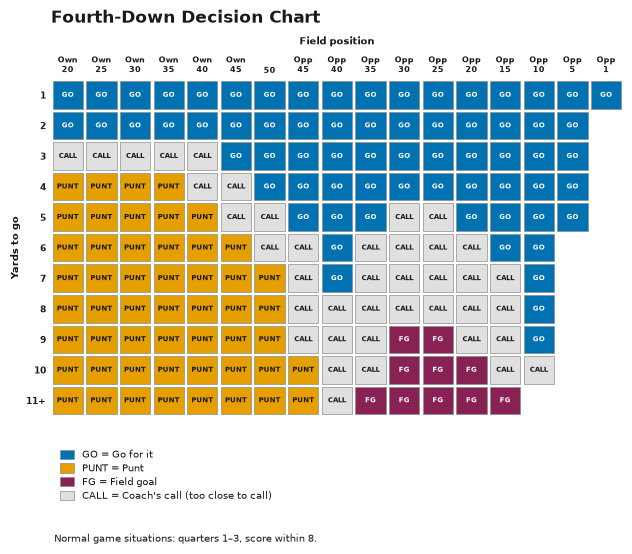

In [27]:
fig = decision_chart(figsize=(PAGE_WIDTH, 5.6), rect=[0.1, 0.25, 0.88, 0.6], title_size=12,
                     word_size=5.3, tick_size=5.8, axis_size=7.5, legend_size=7, legend_y=0.205, foot_y=0.025)
fig.savefig(FIGURES / "fig1_ep_decision_chart.png", dpi=DPI)
plt.show()

*Figure 1. Fourth-down decision chart: the option worth the most expected points for an average team in normal game situations.*

### Figure 2: Conversion rates

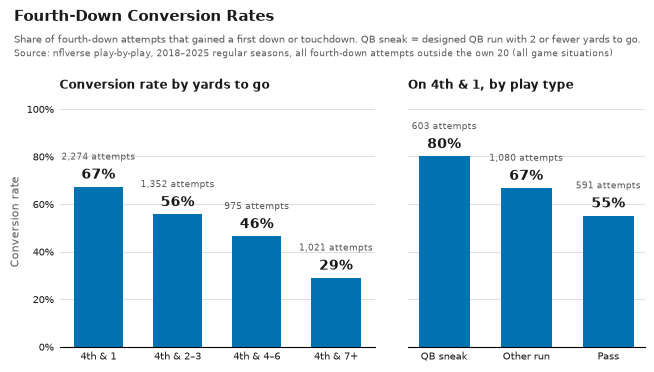

In [28]:
b_dist = pd.read_csv(TABLES / "B_conversion_by_distance.csv", dtype={"distance": str})
b_play = pd.read_csv(TABLES / "B_conversion_by_play_type.csv", dtype={"distance": str})
b_play = (b_play[b_play["distance"] == "1"]
          .set_index("play_group").loc[["QB sneak", "Other run", "Pass"]].reset_index())

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(PAGE_WIDTH, 3.9), sharey=True,
                                 gridspec_kw={"width_ratios": [4, 3], "wspace": 0.12})
fig.subplots_adjust(left=0.09, right=0.99, top=0.74, bottom=0.1)


def conversion_bars(ax, labels, rates, attempts, title):
    """Bars of conversion rate, each labeled with the rate and the number of attempts."""
    x = np.arange(len(labels))
    ax.bar(x, rates, width=0.62, color=GO_BLUE, zorder=2)
    for xi, r, n in zip(x, rates, attempts):
        ax.text(xi, r + 0.02, f"{r:.0%}", ha="center", va="bottom", fontsize=10, fontweight="bold")
        ax.text(xi, r + 0.02 + 0.085, f"{n:,} attempts", ha="center", va="bottom", fontsize=6.5, color=MUTED)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_title(title, loc="left", fontsize=8.5, fontweight="bold", pad=6)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", color=GRID, linewidth=0.6, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0, labelsize=7.5)


conversion_bars(ax_l, [DIST_LABEL[d] for d in b_dist["distance"]], b_dist["conversion_rate"],
                b_dist["attempts"], "Conversion rate by yards to go")
conversion_bars(ax_r, b_play["play_group"], b_play["conversion_rate"], b_play["attempts"],
                "On 4th & 1, by play type")
ax_l.set_ylabel("Conversion rate", fontsize=8, color=MUTED)

fig.text(0.02, 0.965, "Fourth-Down Conversion Rates", fontsize=11, fontweight="bold", va="top")
fig.text(0.02, 0.9, "Share of fourth-down attempts that gained a first down or touchdown. "
         "QB sneak = designed QB run with 2 or fewer yards to go.", fontsize=7, color=MUTED, va="top")
fig.text(0.02, 0.865, SOURCE_ATTEMPTS, fontsize=6.5, color=MUTED, va="top")

fig.savefig(FIGURES / "fig2_how_to_go_for_it.png", dpi=DPI)
plt.show()

*Figure 2. Fourth-down conversion rate by yards to go, and on 4th & 1 by play type (2018–2025, all game situations).*

### Sideline card

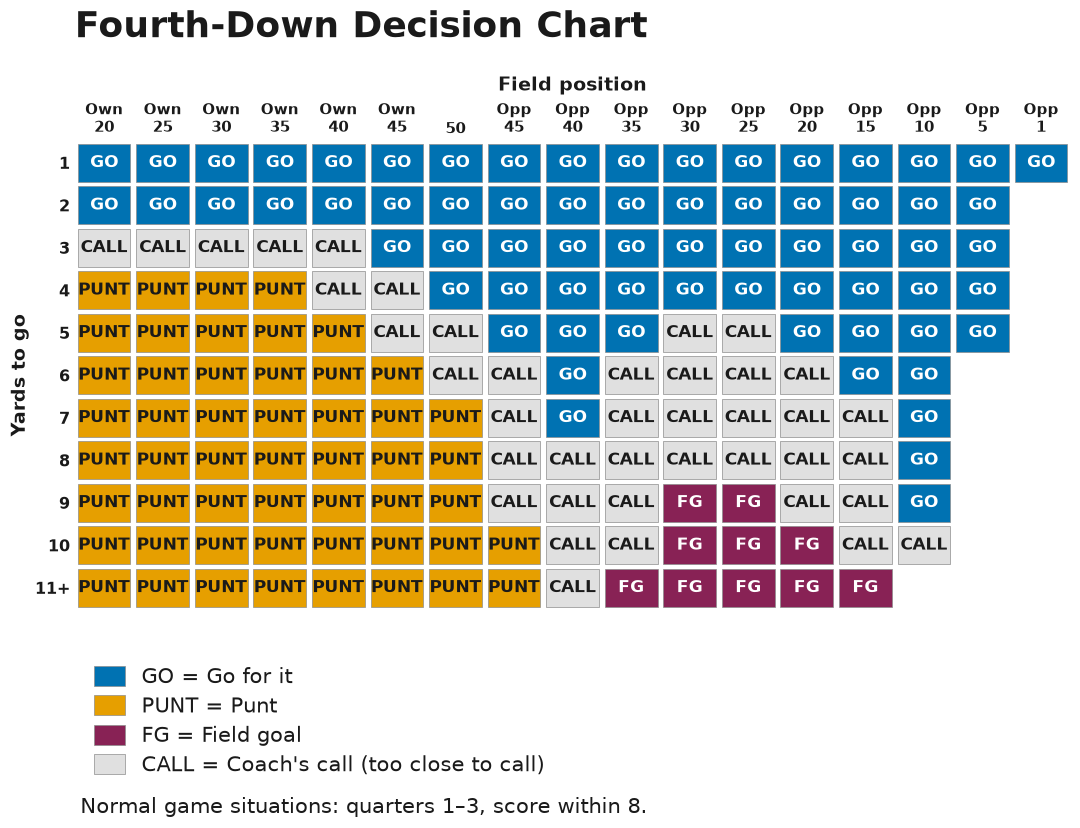

In [29]:
fig = decision_chart(figsize=(11, 8.5), rect=[0.08, 0.27, 0.905, 0.55], title_size=26,
                     word_size=12, tick_size=10.5, axis_size=14, legend_size=15, legend_y=0.225, foot_y=0.03)
fig.savefig(FIGURES / "sideline_decision_card.png", dpi=DPI)
fig.savefig(FIGURES / "sideline_decision_card.pdf")
plt.show()